[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LucaswasTaken/Openhardware-hpc/blob/master/notebooks/Aula2_GPU.ipynb)

# Aula 2 — GPU: paralelismo massivo
### Computação de Alto Desempenho em Python para Engenharia Civil

| Tempo | Bloco |
|---|---|
| 0:00–0:25 | 1. CPU × GPU: poucos núcleos espertos, milhares de núcleos simples |
| 0:25–0:50 | 2. CPU e GPU ainda são mundos separados? (memória unificada) |
| 0:50–1:05 | 3. CuPy: NumPy na GPU e como medir direito |
| 1:05–1:45 | 4. Escrevendo kernels: grid, block e thread |
| 1:45–2:00 | ☕ Intervalo |
| 2:00–3:00 | 5. Projeto: equação do calor numa laje (CPU → GPU) |
| 3:00–3:30 | 6. Quando usar GPU? Checklist e exercícios |

**Antes de começar (Colab):** menu *Ambiente de execução → Alterar o tipo de ambiente de execução → **T4 GPU***.
Células que começam com `%%gpu` só rodam se houver GPU (sem GPU, elas avisam e pulam).

In [1]:
# Preparação: GPU, bibliotecas e registro de resultados
import json, os, sys, time, platform, pathlib, datetime, warnings
import numpy as np
warnings.filterwarnings("ignore", message=".*CUDA path could not be detected.*")
warnings.filterwarnings("ignore", message=".*under-utilization due to low occupancy.*")
import matplotlib.pyplot as plt

NO_COLAB = "google.colab" in sys.modules
if NO_COLAB:
    %pip install -q "numba-cuda[cu12]" array-api-compat

try:
    import cupy as cp
    GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception as erro:                      # sem CuPy ou sem placa NVIDIA
    cp, GPU = None, False
    print("Sem GPU:", erro)

from IPython.core.magic import register_cell_magic
@register_cell_magic
def gpu(linha, celula):
    """%%gpu no topo da célula: roda só se houver GPU."""
    if not GPU:
        print("⏭️  célula de GPU pulada (sem GPU). No Colab: Ambiente de execução → T4 GPU.")
        return
    get_ipython().run_cell(celula)

MAQUINA = "colab" if NO_COLAB else "local"
RESULTADOS = {"maquina": MAQUINA, "python": platform.python_version(), "data": datetime.date.today().isoformat()}

def registrar(chave, **valores):
    RESULTADOS[chave] = valores
    pasta = pathlib.Path("results"); pasta.mkdir(exist_ok=True)
    (pasta / f"aula2_{MAQUINA}.json").write_text(json.dumps(RESULTADOS, indent=1, ensure_ascii=False), encoding="utf-8")
    return valores

def sincroniza():
    if GPU: cp.cuda.Device().synchronize()

def cronometro(f, *args, repeticoes=5, aquecer=True, **kw):
    """Menor tempo de várias execuções; aquece antes (compilação, cache) e sincroniza a GPU."""
    if aquecer: f(*args, **kw)
    melhores = []
    for _ in range(repeticoes):
        sincroniza(); t = time.perf_counter(); f(*args, **kw); sincroniza()
        melhores.append(time.perf_counter() - t)
    return min(melhores)
print(f"Python {platform.python_version()} · NumPy {np.__version__} · CuPy {cp.__version__ if cp else '—'} · GPU: {GPU}")

Python 3.12.13 · NumPy 2.4.6 · CuPy 14.2.0 · GPU: True


## 1. CPU × GPU  ·  0:00–0:25
> 🎬 **Vídeo (1 min):** [CPU × GPU: milhares de núcleos simples](https://lucaswastaken.github.io/Openhardware-hpc/#v07)

| | CPU | GPU |
|---|---|---|
| Núcleos | poucos (2–64), complexos | milhares, simples |
| Otimizada para | **latência**: terminar *uma* tarefa rápido | **vazão**: terminar *muitas* tarefas iguais |
| Execução | cada núcleo segue seu caminho | grupos de 32 threads (*warp*) executam **a mesma instrução** (SIMT) |
| Memória | cache grande, RAM ~50–100 GB/s | cache pequeno, VRAM ~300–3000 GB/s |
| Bom para | lógica com `if`, recursão, tarefas diferentes | a mesma conta em milhões de dados |

Analogia: a CPU é uma equipe de 8 engenheiros sêniores; a GPU é uma obra com 2 500 operários que fazem bem uma tarefa por vez — **todos juntos**.

In [2]:
%%gpu
p = cp.cuda.runtime.getDeviceProperties(0)
cc = (p["major"], p["minor"])
nucleos_por_sm = {(7, 5): 64, (8, 0): 64, (8, 6): 128, (8, 7): 128, (8, 9): 128, (9, 0): 128}.get(cc, 128)
banda = 2 * p.get("memoryClockRate", 0) * 1e3 * p.get("memoryBusWidth", 0) / 8 / 1e9
nome = p["name"].decode() if isinstance(p["name"], bytes) else p["name"]
print(f"GPU: {nome} (compute capability {cc[0]}.{cc[1]})")
print(f"  {p['multiProcessorCount']} SMs × {nucleos_por_sm} núcleos = {p['multiProcessorCount'] * nucleos_por_sm:,} núcleos CUDA")
print(f"  memória: {p['totalGlobalMem'] / 2**30:.1f} GiB · banda teórica ≈ {banda:.0f} GB/s · warp = {p['warpSize']} threads")
registrar("gpu", nome=nome, cc=f"{cc[0]}.{cc[1]}", sms=p["multiProcessorCount"], nucleos=p["multiProcessorCount"] * nucleos_por_sm,
          memoria_gib=p["totalGlobalMem"] / 2**30, banda_gbs=banda)

GPU: NVIDIA GeForce MX570 A (compute capability 8.6)
  16 SMs × 128 núcleos = 2,048 núcleos CUDA
  memória: 4.0 GiB · banda teórica ≈ 96 GB/s · warp = 32 threads


{'nome': 'NVIDIA GeForce MX570 A',
 'cc': '8.6',
 'sms': 16,
 'nucleos': 2048,
 'memoria_gib': 3.99957275390625,
 'banda_gbs': 96.016}

## 2. CPU e GPU ainda são mundos separados?  ·  0:25–0:50
> 🎬 **Vídeo (2 min):** [CPU e GPU: dois mundos ou um só?](https://lucaswastaken.github.io/Openhardware-hpc/#v08b)

Por muito tempo a regra foi: **a GPU tem a sua memória**; antes de calcular, copie os dados da RAM para a VRAM pelo barramento PCIe, e depois copie de volta. Hoje o hardware está mudando:

| Modelo | Exemplos | Memória | Cópia explícita? |
|---|---|---|---|
| **GPU discreta + PCIe** | T4 do Colab, placas GeForce/RTX, a maioria dos clusters | RAM e VRAM separadas, PCIe ~16–64 GB/s | sim (ou migração automática de páginas) |
| **CPU+GPU coerentes, link rápido** | NVIDIA Grace Hopper / Grace Blackwell (NVLink-C2C ~900 GB/s), DGX Spark | duas memórias, **um espaço de endereços coerente** | não precisa |
| **Memória física única (APU)** | Apple M1–M5, AMD MI300A (supercomputador El Capitan), AMD Ryzen AI Max, Intel Lunar Lake | **uma só** memória para CPU e GPU | não existe cópia |

**O que muda:** acabam as cópias e o "pedágio" do PCIe; modelos grandes cabem numa memória só; o código fica mais simples.
**O que NÃO muda:** a GPU continua sendo milhares de núcleos simples em *warps*; continua exigindo **paralelismo de dados** de sobra; **largura de banda e localidade** continuam mandando. Unificar a memória não transforma um laço sequencial em paralelo.

E no T4 (GPU discreta)? O CUDA oferece **memória gerenciada** (*managed / unified memory*): um ponteiro só, válido na CPU e na GPU. Mas é uma **ilusão de software** — por baixo, as páginas **migram** pelo PCIe quando um lado acessa. Vamos medir.

In [3]:
%%gpu
from numba import cuda

N = (1 << 26) if p["totalGlobalMem"] > 4 * 2**30 else (1 << 25)     # 64 M ou 32 M floats
BLOCOS = (N + 255) // 256

@cuda.jit
def escala(x, a):
    i = cuda.grid(1)
    if i < x.size:
        x[i] = a * x[i] + 1.0

def mede(f):
    cuda.synchronize(); t = time.perf_counter(); f(); cuda.synchronize()
    return (time.perf_counter() - t) * 1e3

h = np.ones(N, np.float32)
d = cuda.device_array(N, np.float32); escala[BLOCOS, 256](d, 1.0)        # aquece
copia = {"CPU→GPU (cópia)": mede(lambda: d.copy_to_device(h)),
         "kernel": mede(lambda: escala[BLOCOS, 256](d, 2.0)),
         "GPU→CPU (cópia)": mede(lambda: d.copy_to_host(h))}

m = cuda.managed_array(N, np.float32)       # memória gerenciada: o MESMO array na CPU e na GPU
m[:] = 1.0                                  # a CPU escreve → páginas estão na RAM
ger = {"1º kernel (páginas migram)": mede(lambda: escala[BLOCOS, 256](m, 2.0)),
       "2º kernel (já na GPU)": mede(lambda: escala[BLOCOS, 256](m, 2.0))}
t = time.perf_counter(); m[::4096] += 1; cuda.synchronize(); ger["CPU toca 1 a cada 4096"] = (time.perf_counter() - t) * 1e3
ger["kernel depois do toque"] = mede(lambda: escala[BLOCOS, 256](m, 2.0))

print(f"{N * 4 / 2**20:.0f} MiB de dados\n— cópia explícita —")
for k, v in copia.items(): print(f"  {k:<28} {v:8.1f} ms")
print("— memória gerenciada —")
for k, v in ger.items(): print(f"  {k:<28} {v:8.1f} ms")
CONCORRENTE = bool(cp.cuda.Device(0).attributes.get("ConcurrentManagedAccess", 0))
print(f"Migração de páginas sob demanda (Linux/Colab): {'sim' if CONCORRENTE else 'não (Windows/GPU antiga: migra tudo a cada kernel)'}")
registrar("memoria_unificada", mib=N * 4 / 2**20, copia_ms=copia, gerenciada_ms=ger, migracao_sob_demanda=CONCORRENTE)

128 MiB de dados
— cópia explícita —
  CPU→GPU (cópia)                  28.3 ms
  kernel                            3.8 ms
  GPU→CPU (cópia)                  29.8 ms
— memória gerenciada —
  1º kernel (páginas migram)      145.8 ms
  2º kernel (já na GPU)             5.1 ms
  CPU toca 1 a cada 4096         1261.5 ms
  kernel depois do toque          157.9 ms
Migração de páginas sob demanda (Linux/Colab): não (Windows/GPU antiga: migra tudo a cada kernel)


{'mib': 128.0,
 'copia_ms': {'CPU→GPU (cópia)': 28.307100059464574,
  'kernel': 3.8395000156015158,
  'GPU→CPU (cópia)': 29.770500026643276},
 'gerenciada_ms': {'1º kernel (páginas migram)': 145.81769984215498,
  '2º kernel (já na GPU)': 5.074300104752183,
  'CPU toca 1 a cada 4096': 1261.460400186479,
  'kernel depois do toque': 157.88019984029233},
 'migracao_sob_demanda': False}

In [4]:
%%gpu
# Prefetch: avisar ANTES onde o dado vai ser usado (só onde há migração sob demanda, como no Colab)
if CONCORRENTE:
    ptr = m.__cuda_array_interface__["data"][0]
    m[:] = 1.0
    s = cp.cuda.Stream.null
    t_pf = mede(lambda: cp.cuda.runtime.memPrefetchAsync(ptr, m.nbytes, 0, s.ptr))
    t_k = mede(lambda: escala[BLOCOS, 256](m, 2.0))
    print(f"prefetch {t_pf:.1f} ms + kernel {t_k:.1f} ms  (compare com o 1º kernel acima: {ger['1º kernel (páginas migram)']:.1f} ms)")
    registrar("prefetch", prefetch_ms=t_pf, kernel_ms=t_k)
else:
    print("Este sistema não migra páginas sob demanda; aqui o prefetch não se aplica.")

Este sistema não migra páginas sob demanda; aqui o prefetch não se aplica.


**Leitura dos números:**
- Com cópia explícita, o **kernel é rápido e a viagem pelo PCIe é cara** — muitas vezes a cópia custa mais que a conta.
- Com memória gerenciada, o código fica mais simples, mas **o custo da viagem continua lá**, só que escondido no 1º kernel. Se a CPU volta a tocar no dado, ele volta pelo PCIe.
- Em hardware de memória **física** única (Apple M, MI300A, Grace com NVLink-C2C), essa viagem praticamente desaparece — e a pergunta passa a ser **"quem processa melhor este dado?"**, não **"quanto custa copiar?"**.

> **Resumo:** a *interface* já é unificada em quase todo lugar; a *física* só é unificada em parte do hardware. Programe pensando em **onde o dado mora**.

**🧠 Teste rápido**
1. Por que o 2º kernel com memória gerenciada é tão mais rápido que o 1º?
2. Num Mac com chip M, faria sentido medir "tempo de cópia CPU→GPU"? Por quê?

## 3. CuPy: NumPy na GPU, e como medir direito  ·  0:50–1:05
> 🎬 **Vídeo (1 min):** [O gargalo das transferências](https://lucaswastaken.github.io/Openhardware-hpc/#v08)

O CuPy imita a API do NumPy: troque `np` por `cp` e a conta roda na GPU. Três regras para medir:
1. **Aqueça** (a 1ª chamada compila e aloca);
2. **Sincronize** (a GPU trabalha em paralelo com a CPU — sem sincronizar, você mede só o *lançamento*);
3. **Separe** cálculo de transferência.

In [5]:
%%gpu
from cupyx.profiler import benchmark

n = 20_000_000
a_h, b_h = np.random.rand(n).astype(np.float32), np.random.rand(n).astype(np.float32)
a_d, b_d = cp.asarray(a_h), cp.asarray(b_h)

t_cpu = cronometro(lambda: a_h + b_h)
t_gpu = cronometro(lambda: a_d + b_d)
t_total = cronometro(lambda: cp.asnumpy(cp.asarray(a_h) + cp.asarray(b_h)))
print(f"soma de {n:,} floats:  CPU {t_cpu*1e3:.1f} ms · GPU só a conta {t_gpu*1e3:.2f} ms ({t_cpu/t_gpu:.0f}×)"
      f" · GPU com as cópias {t_total*1e3:.1f} ms ({t_cpu/t_total:.2f}×)")
print(benchmark(lambda: a_d + b_d, n_repeat=20))
registrar("soma_vetores", cpu_ms=t_cpu*1e3, gpu_ms=t_gpu*1e3, gpu_com_copias_ms=t_total*1e3)

soma de 20,000,000 floats:  CPU 34.9 ms · GPU só a conta 3.38 ms (10×) · GPU com as cópias 60.5 ms (0.58×)
<lambda>            :    CPU:  1285.445 us   +/- 320.624 (min:   698.100 / max:  1984.300) us     GPU-0:  3943.573 us   +/- 318.716 (min:  3375.104 / max:  4645.888) us


{'cpu_ms': 34.932299982756376,
 'gpu_ms': 3.381999908015132,
 'gpu_com_copias_ms': 60.54480001330376}

A soma faz **1 conta para cada 12 bytes** movidos: é limitada pela memória, e o PCIe é mais lento que a RAM. Já a multiplicação de matrizes faz $2n^3$ contas sobre $3n^2$ números — **muita conta por byte** — e aí a GPU dispara. Repare também na diferença entre `float32` e `float64` (GPUs de consumo, como T4 e GeForce, são muito mais lentas em precisão dupla).

In [6]:
%%gpu
linhas = []
for n in (1024, 2048, 4096):
    A = np.random.rand(n, n).astype(np.float32)
    t_cpu = cronometro(lambda: A @ A, repeticoes=2)
    for tipo in (cp.float32, cp.float64):
        Ad = cp.asarray(A, dtype=tipo)
        t_gpu = cronometro(lambda: Ad @ Ad, repeticoes=3)
        erro = float(cp.abs(Ad @ Ad - cp.asarray(A @ A, dtype=tipo)).max() / (n * 1.0))
        linhas.append((n, np.dtype(tipo).name, t_cpu, t_gpu))
        print(f"n={n}  {np.dtype(tipo).name}:  CPU(float32) {2*n**3/t_cpu/1e9:7.0f} GFLOP/s · GPU {2*n**3/t_gpu/1e9:7.0f} GFLOP/s"
              f"  → {t_cpu/t_gpu:5.1f}×   erro relativo {erro:.1e}")
registrar("matmul", linhas=[dict(n=a, tipo=b, cpu_s=c, gpu_s=d) for a, b, c, d in linhas])

n=1024  float32:  CPU(float32)     306 GFLOP/s · GPU    1391 GFLOP/s  →   4.5×   erro relativo 3.0e-07


n=1024  float64:  CPU(float32)     306 GFLOP/s · GPU      38 GFLOP/s  →   0.1×   erro relativo 1.8e-07


n=2048  float32:  CPU(float32)     251 GFLOP/s · GPU    1497 GFLOP/s  →   6.0×   erro relativo 4.5e-07


n=2048  float64:  CPU(float32)     251 GFLOP/s · GPU      39 GFLOP/s  →   0.2×   erro relativo 1.4e-07


n=4096  float32:  CPU(float32)     239 GFLOP/s · GPU    1799 GFLOP/s  →   7.5×   erro relativo 3.3e-07


n=4096  float64:  CPU(float32)     239 GFLOP/s · GPU      39 GFLOP/s  →   0.2×   erro relativo 1.3e-07


{'linhas': [{'n': 1024,
   'tipo': 'float32',
   'cpu_s': 0.007008000044152141,
   'gpu_s': 0.0015438999980688095},
  {'n': 1024,
   'tipo': 'float64',
   'cpu_s': 0.007008000044152141,
   'gpu_s': 0.05707159987650812},
  {'n': 2048,
   'tipo': 'float32',
   'cpu_s': 0.06849570013582706,
   'gpu_s': 0.011472900165244937},
  {'n': 2048,
   'tipo': 'float64',
   'cpu_s': 0.06849570013582706,
   'gpu_s': 0.44511600001715124},
  {'n': 4096,
   'tipo': 'float32',
   'cpu_s': 0.5750512999948114,
   'gpu_s': 0.07639780011959374},
  {'n': 4096,
   'tipo': 'float64',
   'cpu_s': 0.5750512999948114,
   'gpu_s': 3.5495001999661326}]}

## 4. Escrevendo kernels: grid, block e thread  ·  1:05–1:45
> 🎬 **Vídeo (1 min):** [Grid, block e thread: escrevendo um kernel](https://lucaswastaken.github.io/Openhardware-hpc/#v09)

Um **kernel** é a função que **cada thread** da GPU executa. As threads se organizam em **blocos** (até 1024 threads, que compartilham memória rápida), e os blocos formam a **grade** (*grid*). Cada thread descobre "quem ela é" pelo índice global: `i = blockIdx.x * blockDim.x + threadIdx.x` — no Numba, `cuda.grid(1)`.

### 4.1 `ElementwiseKernel` do CuPy: tensão de von Mises
Para milhões de pontos de integração com $(\sigma_x, \sigma_y, \tau_{xy})$: $\sigma_{vm} = \sqrt{\sigma_x^2 - \sigma_x\sigma_y + \sigma_y^2 + 3\tau_{xy}^2}$. O CuPy escreve o laço e a grade para você: basta a conta de **um** elemento, em C.

In [7]:
%%gpu
von_mises = cp.ElementwiseKernel(
    "float32 sx, float32 sy, float32 txy", "float32 vm",
    "vm = sqrtf(sx*sx - sx*sy + sy*sy + 3.0f*txy*txy)", "von_mises")

n = 30_000_000
rng = cp.random.default_rng(1)
sx, sy, txy = (rng.standard_normal(n, dtype=cp.float32) * 100 for _ in range(3))
t_k = cronometro(von_mises, sx, sy, txy)
t_cp = cronometro(lambda: cp.sqrt(sx*sx - sx*sy + sy*sy + 3*txy*txy))
sx_h, sy_h, txy_h = cp.asnumpy(sx), cp.asnumpy(sy), cp.asnumpy(txy)
t_np = cronometro(lambda: np.sqrt(sx_h*sx_h - sx_h*sy_h + sy_h*sy_h + 3*txy_h*txy_h), repeticoes=2)
print(f"NumPy (CPU) {t_np*1e3:.0f} ms · CuPy expressão {t_cp*1e3:.1f} ms · ElementwiseKernel {t_k*1e3:.1f} ms"
      f"  ({t_cp/t_k:.1f}× sobre a expressão: 1 passada na memória em vez de várias)")
registrar("von_mises", numpy_ms=t_np*1e3, cupy_ms=t_cp*1e3, kernel_ms=t_k*1e3)

NumPy (CPU) 585 ms · CuPy expressão 31.7 ms · ElementwiseKernel 6.0 ms  (5.3× sobre a expressão: 1 passada na memória em vez de várias)


{'numpy_ms': 584.5348001457751,
 'cupy_ms': 31.697200145572424,
 'kernel_ms': 5.99190010689199}

### 4.2 Numba-CUDA: Monte Carlo com gerador aleatório por thread
Estimativa de π (o mesmo princípio da probabilidade de falha da Aula 1): cada thread sorteia `amostras` pontos com o **seu próprio** gerador (xoroshiro128+) e conta quantos caem no círculo.

In [8]:
%%gpu
from numba.cuda.random import create_xoroshiro128p_states, xoroshiro128p_uniform_float32

@cuda.jit
def conta_no_circulo(estados, amostras, saida):
    i = cuda.grid(1)                       # índice global desta thread
    if i < saida.size:
        dentro = 0
        for _ in range(amostras):
            x = xoroshiro128p_uniform_float32(estados, i)
            y = xoroshiro128p_uniform_float32(estados, i)
            if x * x + y * y <= 1.0:
                dentro += 1
        saida[i] = dentro

THREADS_POR_BLOCO = 256
BLOCOS_MC = 32 * p["multiProcessorCount"]            # vários blocos por SM para esconder latência
n_threads = THREADS_POR_BLOCO * BLOCOS_MC
estados = create_xoroshiro128p_states(n_threads, seed=42)
saida = cuda.device_array(n_threads, dtype=np.int32)
AMOSTRAS = 2000

def pi_numba():
    conta_no_circulo[BLOCOS_MC, THREADS_POR_BLOCO](estados, AMOSTRAS, saida)
    return 4 * saida.copy_to_host().sum() / (n_threads * AMOSTRAS)

def pi_cupy(n=n_threads * AMOSTRAS // 8):
    x, y = cp.random.random(n, dtype=cp.float32), cp.random.random(n, dtype=cp.float32)
    return 4 * float((x * x + y * y <= 1).sum()) / n

t_nb = cronometro(pi_numba, repeticoes=3)
t_cpv = cronometro(pi_cupy, repeticoes=3) * 8            # mesmo nº de amostras
print(f"grade = {BLOCOS_MC} blocos × {THREADS_POR_BLOCO} threads = {n_threads:,} threads; {n_threads*AMOSTRAS/1e9:.2f} bilhões de amostras")
print(f"Numba-CUDA: π ≈ {pi_numba():.6f} em {t_nb*1e3:.0f} ms ({n_threads*AMOSTRAS/t_nb/1e9:.1f} G amostras/s)")
print(f"CuPy vetorizado: {t_cpv*1e3:.0f} ms equivalentes — gera e guarda arrays enormes; o kernel não guarda nada")
registrar("pi_monte_carlo", amostras=n_threads*AMOSTRAS, numba_ms=t_nb*1e3, cupy_ms=t_cpv*1e3)

grade = 512 blocos × 256 threads = 131,072 threads; 0.26 bilhões de amostras
Numba-CUDA: π ≈ 3.141555 em 75 ms (3.5 G amostras/s)
CuPy vetorizado: 182 ms equivalentes — gera e guarda arrays enormes; o kernel não guarda nada


{'amostras': 262144000,
 'numba_ms': 75.48650004900992,
 'cupy_ms': 182.41919949650764}

**🧠 Teste rápido**
1. Por que lançamos muito mais threads do que a GPU tem de núcleos?
2. O `if i < saida.size` é necessário. O que aconteceria sem ele?

---
## ☕ Intervalo · 1:45–2:00

## 5. Projeto: equação do calor numa laje  ·  2:00–3:00
> 🎬 **Vídeo (1 min):** [Equação do calor na GPU, passo a passo](https://lucaswastaken.github.io/Openhardware-hpc/#v10)

Laje de concreto (corte 2D) com a face inferior exposta a incêndio (600 °C) e as outras a 20 °C. A temperatura evolui por $\partial T/\partial t = \alpha \nabla^2 T$. Com diferenças finitas explícitas, cada ponto da malha é atualizado pela média dos vizinhos:

$$T^{n+1}_{i,j} = T^n_{i,j} + r\,(T^n_{i+1,j} + T^n_{i-1,j} + T^n_{i,j+1} + T^n_{i,j-1} - 4T^n_{i,j}), \qquad r = \alpha\,\Delta t/\Delta x^2 \le 0{,}25$$

Milhões de pontos, todos atualizados **ao mesmo tempo** a cada passo: perfeito para GPU. Vamos do Python puro à GPU — e escrever **uma única função** que roda em NumPy e em CuPy (padrão *Array API*).

In [9]:
from array_api_compat import array_namespace
from numba import njit, prange

R = 0.24

def laje_inicial(n, xp=np):
    T = xp.full((n, n), 20.0, dtype=xp.float32)
    T[-1, :] = 600.0                            # face inferior: incêndio
    return T

def simula_python(T, passos):
    T = [list(map(float, linha)) for linha in T]
    n = len(T)
    for _ in range(passos):
        N = [linha[:] for linha in T]
        for i in range(1, n - 1):
            for j in range(1, n - 1):
                N[i][j] = T[i][j] + R * (T[i+1][j] + T[i-1][j] + T[i][j+1] + T[i][j-1] - 4 * T[i][j])
        T = N
    return np.array(T, dtype=np.float32)

def simula(T, passos):
    """Uma função, qualquer biblioteca de arrays: NumPy (CPU) ou CuPy (GPU)."""
    xp = array_namespace(T)
    A, B = T, xp.asarray(T, copy=True)
    for _ in range(passos):
        B[1:-1, 1:-1] = A[1:-1, 1:-1] + R * (A[2:, 1:-1] + A[:-2, 1:-1] + A[1:-1, 2:] + A[1:-1, :-2] - 4 * A[1:-1, 1:-1])
        A, B = B, A
    return A

@njit(parallel=True, cache=True)
def simula_numba(T, passos):
    A, B = T.copy(), T.copy()
    n = T.shape[0]
    for _ in range(passos):
        for i in prange(1, n - 1):
            for j in range(1, n - 1):
                B[i, j] = A[i, j] + R * (A[i+1, j] + A[i-1, j] + A[i, j+1] + A[i, j-1] - 4 * A[i, j])
        A, B = B, A
    return A

ref = simula_python(laje_inicial(48), 100)
assert np.allclose(simula(laje_inicial(48), 100), ref, atol=1e-3)
assert np.allclose(simula_numba(laje_inicial(48), 100), ref, atol=1e-3)
print("NumPy e Numba conferem com o Python puro ✓")

NumPy e Numba conferem com o Python puro ✓


**Na GPU, duas versões:** a função `simula` com CuPy (fatias → cria arrays temporários a cada passo) e um **kernel 2D** em Numba-CUDA, em que cada thread atualiza **um ponto** da malha, lendo e escrevendo a memória uma única vez. A grade agora é 2D: blocos de 16×16 threads cobrindo a laje.

In [10]:
%%gpu
@cuda.jit
def passo_calor(A, B, r):
    i, j = cuda.grid(2)                              # linha e coluna desta thread
    if 0 < i < A.shape[0] - 1 and 0 < j < A.shape[1] - 1:
        B[i, j] = A[i, j] + r * (A[i+1, j] + A[i-1, j] + A[i, j+1] + A[i, j-1] - 4 * A[i, j])

def simula_cuda(T, passos):
    A, B = cuda.to_device(T), cuda.to_device(T)
    bloco = (16, 16)
    grade = ((T.shape[0] + 15) // 16, (T.shape[1] + 15) // 16)
    for _ in range(passos):
        passo_calor[grade, bloco](A, B, np.float32(R))
        A, B = B, A
    return A.copy_to_host()

assert np.allclose(simula_cuda(laje_inicial(48), 100), ref, atol=1e-3)
print("Kernel 2D confere com o Python puro ✓")

Kernel 2D confere com o Python puro ✓


n= 128 ( 0.02 M pontos): Python puro 1.099s  NumPy 0.013s  Numba paralelo 0.005s  CuPy (GPU) 0.059s  Numba-CUDA kernel (GPU) 0.020s


n= 256 ( 0.07 M pontos): NumPy 0.062s  Numba paralelo 0.006s  CuPy (GPU) 0.074s  Numba-CUDA kernel (GPU) 0.022s


n= 512 ( 0.26 M pontos): NumPy 0.290s  Numba paralelo 0.014s  CuPy (GPU) 0.088s  Numba-CUDA kernel (GPU) 0.031s


n=1024 ( 1.05 M pontos): NumPy 4.117s  Numba paralelo 0.060s  CuPy (GPU) 0.293s  Numba-CUDA kernel (GPU) 0.105s


n=2048 ( 4.19 M pontos): Numba paralelo 0.479s  CuPy (GPU) 1.124s  Numba-CUDA kernel (GPU) 0.406s


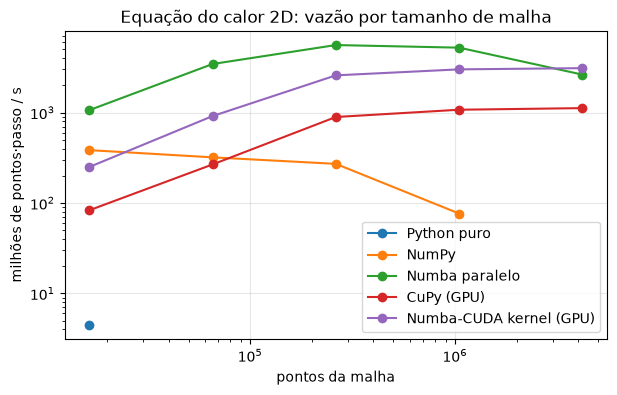

{'passos': 300,
 'tempos': {'Python puro': {'128': 1.0994657999835908},
  'NumPy': {'128': 0.012796299997717142,
   '256': 0.061504399869591,
   '512': 0.2903844998218119,
   '1024': 4.117150700185448},
  'Numba paralelo': {'128': 0.004625299945473671,
   '256': 0.0057131999637931585,
   '512': 0.014102700166404247,
   '1024': 0.06028459989465773,
   '2048': 0.47902199998497963},
  'CuPy (GPU)': {'128': 0.05917849997058511,
   '256': 0.07369740004651248,
   '512': 0.08806570013985038,
   '1024': 0.29281309992074966,
   '2048': 1.1238772999495268},
  'Numba-CUDA kernel (GPU)': {'128': 0.019658799981698394,
   '256': 0.021504100179299712,
   '512': 0.030503700021654367,
   '1024': 0.1047573999967426,
   '2048': 0.40621240017935634}}}

In [11]:
PASSOS = 300
tamanhos = [128, 256, 512, 1024, 2048]
tempos = {"Python puro": {}, "NumPy": {}, "Numba paralelo": {}, "CuPy (GPU)": {}, "Numba-CUDA kernel (GPU)": {}}
for n in tamanhos:
    T0 = laje_inicial(n)
    if n <= 128:
        tempos["Python puro"][n] = cronometro(simula_python, T0, PASSOS, repeticoes=1, aquecer=False)
    if n <= 1024:
        tempos["NumPy"][n] = cronometro(simula, T0, PASSOS, repeticoes=2)
    tempos["Numba paralelo"][n] = cronometro(simula_numba, T0, PASSOS, repeticoes=2)
    if GPU:
        T0_d = laje_inicial(n, cp)
        tempos["CuPy (GPU)"][n] = cronometro(simula, T0_d, PASSOS, repeticoes=3)
        tempos["Numba-CUDA kernel (GPU)"][n] = cronometro(simula_cuda, T0, PASSOS, repeticoes=3)
    print(f"n={n:>4} ({n*n/1e6:5.2f} M pontos): " + "  ".join(f"{k} {v[n]:.3f}s" for k, v in tempos.items() if n in v))

fig, ax = plt.subplots(figsize=(7, 4))
for k, v in tempos.items():
    if v:
        ax.plot([n * n for n in v], [PASSOS * n * n / t / 1e6 for n, t in v.items()], "o-", label=k)
ax.set(xscale="log", yscale="log", xlabel="pontos da malha", ylabel="milhões de pontos·passo / s",
       title="Equação do calor 2D: vazão por tamanho de malha")
ax.legend(); ax.grid(alpha=.3); plt.show()
registrar("calor", passos=PASSOS, tempos={k: {str(n): t for n, t in v.items()} for k, v in tempos.items()})

**Leitura do gráfico:**
- Para malhas **pequenas** a GPU quase não ganha: há pouco trabalho para milhares de núcleos, e cada passo tem um custo fixo de lançamento. A vazão da GPU cresce com o tamanho da malha (escalabilidade fraca na prática).
- O **kernel próprio** vence a versão com fatias do CuPy: uma passada pela memória em vez de várias.
- Este problema é **limitado pela memória** (poucas contas por ponto). Por isso vence quem tem **mais largura de banda**: no Colab (2 núcleos de CPU × T4 com ~320 GB/s), a GPU ganha com folga; num notebook com CPU forte e GPU de entrada (ex.: GeForce MX, ~100 GB/s), o Numba na CPU pode empatar. **Meça no seu hardware antes de concluir.**

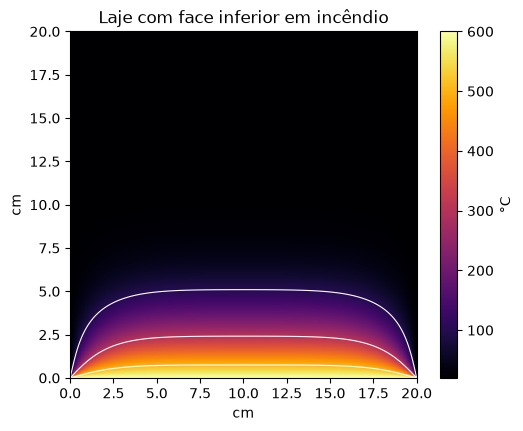

In [12]:
# Resultado de engenharia: temperatura na laje (20 cm) após o aquecimento
n = 256
T = simula(laje_inicial(n, cp) if GPU else laje_inicial(n), 4000)
T = cp.asnumpy(T) if GPU else T
plt.figure(figsize=(6, 4.5))
plt.imshow(T, cmap="inferno", extent=[0, 20, 0, 20]); plt.colorbar(label="°C")
plt.contour(T, levels=[100, 300, 500], colors="w", linewidths=.8, extent=[0, 20, 20, 0])
plt.title("Laje com face inferior em incêndio"); plt.xlabel("cm"); plt.ylabel("cm"); plt.show()

> **A mesma função `simula`** rodou na CPU e na GPU: o padrão *Array API* (NumPy ≥ 2, CuPy, PyTorch, JAX) permite escrever o código uma vez e escolher **onde** ele roda. Em máquinas de memória unificada, essa escolha fica ainda mais barata.

**Para casa:** troque a borda superior por convecção (condição de Robin) ou use um $r$ maior que 0,25 e observe a instabilidade numérica.

## 6. Quando usar GPU?  ·  3:00–3:30

**Checklist rápido**
1. **Há paralelismo de dados?** A mesma conta em milhões de elementos/pontos/amostras → ✅. Lógica diferente para cada item → CPU.
2. **Muita conta por byte?** (matmul, kernels com laços internos, Monte Carlo) → GPU ganha muito. Pouca conta por byte (soma de vetores) → só ganha se o dado **já estiver** na GPU.
3. **Onde o dado mora?** Faça o máximo de passos na GPU antes de trazer de volta. Em memória unificada, essa conta muda.
4. **Precisão:** `float32` é muito mais rápido em GPUs de consumo; confira se a precisão basta.
5. **Mediu direito?** Aquecer, sincronizar, separar transferência, repetir.

| Ferramenta | Use para |
|---|---|
| CuPy | trocar `np` → `cp`; álgebra linear, FFT, arrays |
| `cp.ElementwiseKernel` / `cp.RawKernel` | uma conta por elemento, sem arrays temporários |
| Numba-CUDA | kernels em Python com laços e lógica |
| Array API (`array_api_compat`) | o mesmo código em CPU e GPU |
| PyTorch / JAX | também servem para cálculo científico, com derivadas automáticas |

### Exercícios
Escolha **um** exercício de [`exercicios/lista.md`](../exercicios/lista.md) e uma tecnologia; use o [modelo de relatório](../exercicios/modelo_relatorio.ipynb).
> 🎬 **Vídeo (1 min):** [Como fazer o relatório](https://lucaswastaken.github.io/Openhardware-hpc/#v11)  ·  Exemplos resolvidos: [vídeos 12–14](https://lucaswastaken.github.io/Openhardware-hpc/#v12)